# 임베딩 실습: 단어 벡터의 코사인 유사도와 군집

무료 임베딩 모델로 단어 30개를 벡터로 바꾼 뒤, 벡터끼리 얼마나 가까운지를 표와 그림으로 확인합니다.

1. 임베딩 모델을 고를 때 볼 벤치마크와 모델 목록 사이트를 확인합니다.
2. 단어를 벡터로 바꾸고, 벡터가 어떤 모양인지 봅니다.
3. 코사인 유사도로 두 단어가 얼마나 가까운지 계산합니다.
4. 최근접 이웃 검색으로 단어마다 가장 가까운 단어를 찾습니다.
5. 군집화 방법 3가지로 단어를 나누고, 모델 3개의 결과를 비교합니다.

**실행 전에 할 일**

- Colab 메뉴 「런타임 → 런타임 유형 변경」에서 **T4 GPU** 를 고르면 빠릅니다. GPU 가 없어도 CPU 로 끝까지 실행됩니다.
- 셀은 위에서부터 차례로 실행합니다. 처음 모델을 내려받을 때 1～2분 걸립니다.

## 0. 임베딩 모델을 고를 때 보는 사이트

**임베딩(embedding)** 은 단어나 문장 하나를 숫자 수백～수천 개로 된 벡터로 바꾼 것입니다. **임베딩 모델** 은 뜻이 가까운 글의 벡터가 가깝게 나오도록 학습한 모델입니다.

임베딩 모델은 공개된 것만 수천 개입니다. 고를 때는 아래 사이트에서 과제별 점수와 크기를 먼저 봅니다.

| 사이트 | 제공 내용 | 확인 항목 |
|---|---|---|
| [MTEB 리더보드](https://huggingface.co/spaces/mteb/leaderboard) | 검색 · 분류 · 군집 · 문장 유사도 과제별 점수와 순위 | 한국어 과제 점수, 모델 크기, 벡터 차원 |
| [MTEB 논문](https://arxiv.org/abs/2210.07316) · [GitHub](https://github.com/embeddings-benchmark/mteb) | 벤치마크가 어떤 과제와 자료로 점수를 매기는지 | 내가 할 일과 같은 과제가 있는지 |
| [Hugging Face 모델 목록(문장 유사도)](https://huggingface.co/models?pipeline_tag=sentence-similarity) | 무료로 내려받을 수 있는 임베딩 모델 전체 | 내려받기 수, 라이선스, 지원 언어 |
| [Sentence Transformers 사전학습 모델 표](https://www.sbert.net/docs/sentence_transformer/pretrained_models.html) | 바로 불러 쓸 수 있는 모델의 속도와 성능 | 다국어 모델인지, 처리 속도 |
| [AutoRAG 한국어 임베딩 벤치마크](https://github.com/Marker-Inc-Korea/AutoRAG-example-korean-embedding-benchmark) | 한국어 문서 검색 과제에서 모델별 점수 | 한국어 검색 성능 |
| [KURE GitHub](https://github.com/nlpai-lab/KURE) | 한국어 검색용 모델 KURE 의 학습 방법과 평가 | 한국어 평가 자료와 점수 |

이 노트북에서 쓰는 무료 모델은 3개입니다. 모두 Hugging Face 에서 바로 내려받습니다.

| 모델 | 벡터 차원 | 파일 크기 | 특징 |
|---|---:|---:|---|
| [nlpai-lab/KURE-v1](https://huggingface.co/nlpai-lab/KURE-v1) | 1,024 | 약 2.1GB | 한국어 검색에 맞춰 학습한 모델, 이 노트북의 기본 모델 |
| [intfloat/multilingual-e5-small](https://huggingface.co/intfloat/multilingual-e5-small) | 384 | 약 0.5GB | 작고 빠른 다국어 모델, 입력 앞에 `query: ` 를 써야 함 |
| [paraphrase-multilingual-MiniLM-L12-v2](https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2) | 384 | 약 0.5GB | 문장 유사도용 다국어 모델 |

리더보드 점수는 그 벤치마크 자료에서 구한 값입니다. 내 자료에서도 점수가 높은지는 내 자료로 직접 비교해야 알 수 있습니다.

이 밖에 많이 쓰이는 모델로 [BAAI/bge-m3](https://huggingface.co/BAAI/bge-m3)(1,024차원, 다국어)가 있습니다.

## 1. 준비

라이브러리를 설치하고, GPU 를 쓸 수 있는지 확인합니다. `koreanize-matplotlib` 는 그림에 한글이 깨지지 않게 해 주는 패키지입니다.

In [ ]:
!pip -q install sentence-transformers umap-learn koreanize-matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 56.0 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 그림의 한글 글꼴
import torch
from sentence_transformers import SentenceTransformer

device = "cuda" if torch.cuda.is_available() else "cpu"
print("사용 장치:", device)

사용 장치: cuda


## 2. 단어 30개의 임베딩

범주 5개에서 단어를 6개씩, 모두 30개 고릅니다. 범주는 정답 확인에만 쓰고, 모델에는 단어만 입력합니다.

In [ ]:
words_by_group = {
    "과일": ["사과", "바나나", "포도", "딸기", "수박", "복숭아"],
    "동물": ["강아지", "고양이", "호랑이", "사자", "토끼", "코끼리"],
    "탈것": ["자동차", "버스", "기차", "비행기", "자전거", "지하철"],
    "직업": ["의사", "간호사", "교사", "요리사", "경찰관", "소방관"],
    "날씨": ["비", "눈", "바람", "태풍", "안개", "장마"],
}
words = [w for ws in words_by_group.values() for w in ws]
groups = [g for g, ws in words_by_group.items() for _ in ws]
print(len(words), "개:", words)

30 개: ['사과', '바나나', '포도', '딸기', '수박', '복숭아', '강아지', '고양이', '호랑이', '사자', '토끼', '코끼리', '자동차', '버스', '기차', '비행기', '자전거', '지하철', '의사', '간호사', '교사', '요리사', '경찰관', '소방관', '비', '눈', '바람', '태풍', '안개', '장마']


KURE-v1 을 불러와 단어 30개를 벡터로 바꿉니다.

`normalize_embeddings=True` 는 **L2 정규화** 옵션입니다. L2 정규화는 벡터의 각 값을 벡터 길이로 나눠 길이를 1 로 만드는 계산입니다. 정규화한 벡터끼리는 내적이 곧 코사인 유사도입니다(「3. 코사인 유사도」).

In [ ]:
model = SentenceTransformer("nlpai-lab/KURE-v1", device=device)
emb = model.encode(words, normalize_embeddings=True)

print("벡터 모양:", emb.shape)          # (단어 수, 차원)
print("「사과」 앞 8개 값:", emb[0][:8].round(3))
print("「사과」 벡터 길이:", np.linalg.norm(emb[0]).round(3))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/220 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/17.3k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/807 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

벡터 모양: (30, 1024)
「사과」 앞 8개 값: [-0.043  0.029 -0.017  0.025 -0.014 -0.04  -0.011  0.02 ]
「사과」 벡터 길이: 1.0


- `(30, 1024)` 는 단어 30개가 각각 1,024차원 벡터가 되었다는 뜻입니다.
- 수 하나하나가 「과일다움」 같은 정해진 뜻을 갖지는 않습니다. 벡터는 다른 벡터와 비교할 때 쓰입니다.
- 벡터 길이가 1.0 인 것은 L2 정규화를 했기 때문입니다.

In [ ]:
vec = model.encode("사과", normalize_embeddings=True)

print("차원:", vec.shape)        # (1024,)
print("앞 10개 값:", vec[:10].round(4))
print("벡터 길이:", np.linalg.norm(vec).round(3))
print("전체 차원:",vec)

차원: (1024,)
앞 10개 값: [-0.0433  0.0293 -0.0167  0.0248 -0.0138 -0.0401 -0.0112  0.0204  0.0075
 -0.0087]
벡터 길이: 1.0
전체 차원: [-0.04331083  0.02933349 -0.0166667  ... -0.02104197  0.00229944
  0.05163432]


## 3. 코사인 유사도

**코사인 유사도(cosine similarity)** 는 두 벡터의 방향이 얼마나 같은지를 나타내는 값입니다.

$$
\cos(\mathbf{a}, \mathbf{b}) = \frac{\mathbf{a} \cdot \mathbf{b}}{\lVert \mathbf{a} \rVert \, \lVert \mathbf{b} \rVert}
$$

- $\mathbf{a} \cdot \mathbf{b}$: 두 벡터의 내적(같은 순서의 값끼리 곱해 더한 값)
- $\lVert \mathbf{a} \rVert$: 벡터 $\mathbf{a}$ 의 길이

2차원 벡터로 계산해 보면 다음과 같습니다.

| a | b | 내적 | 길이 곱 | 코사인 |
|---|---|---:|---:|---:|
| (3, 4) | (4, 3) | 3×4 + 4×3 = 24 | 5 × 5 = 25 | 0.96 |
| (1, 0) | (0, 1) | 0 | 1 × 1 = 1 | 0 |
| (1, 0) | (−1, 0) | −1 | 1 × 1 = 1 | −1 |

방향이 같으면 1, 직각이면 0, 반대면 −1 입니다. 정규화한 벡터는 분모가 1 이라 내적이 곧 코사인입니다.

In [ ]:
sim = emb @ emb.T   # 30 × 30 코사인 유사도 행렬
sim_df = pd.DataFrame(sim, index=words, columns=words)

pairs = [("강아지", "고양이"), ("버스", "지하철"), ("의사", "간호사"),
         ("사과", "바나나"), ("사과", "자동차"), ("태풍", "바람")]
pd.DataFrame([(a, b, round(sim_df.loc[a, b], 3)) for a, b in pairs],
             columns=["단어 1", "단어 2", "코사인"])

,단어 1,단어 2,코사인
0,강아지,고양이,0.790
1,버스,지하철,0.656
2,의사,간호사,0.663
3,사과,바나나,0.474
4,사과,자동차,0.466
5,태풍,바람,0.644


코사인 유사도 30 × 30 행렬을 히트맵으로 그립니다. 단어를 범주 순서대로 배치했으므로, 대각선을 따라 6 × 6 정사각형이 진하게 보이면 같은 범주끼리 가깝다는 뜻입니다.

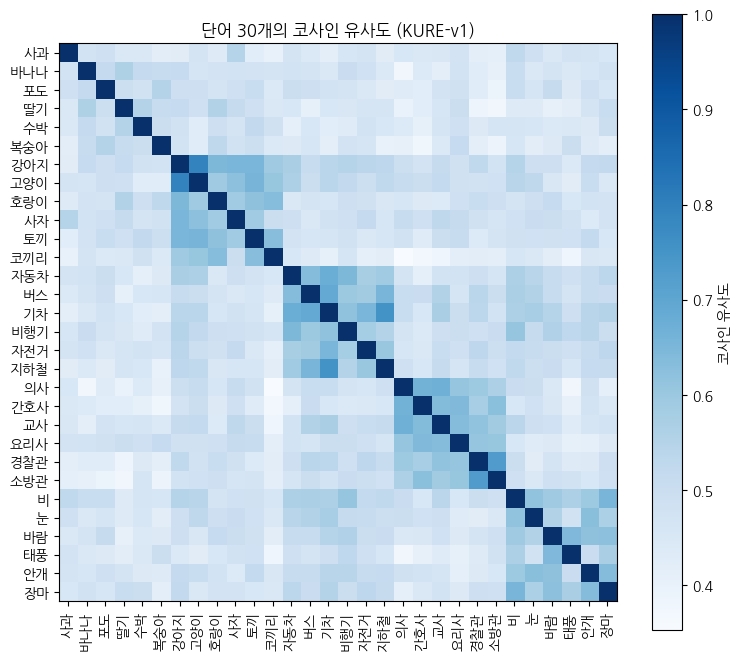

In [ ]:
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(sim, cmap="Blues")
ax.set_xticks(range(len(words)), words, rotation=90)
ax.set_yticks(range(len(words)), words)
fig.colorbar(im, ax=ax, label="코사인 유사도")
ax.set_title("단어 30개의 코사인 유사도 (KURE-v1)")
plt.show()

In [ ]:
same = [sim[i, j] for i in range(30) for j in range(30) if i != j and groups[i] == groups[j]]
diff = [sim[i, j] for i in range(30) for j in range(30) if groups[i] != groups[j]]
print(f"같은 범주 쌍의 평균 코사인: {np.mean(same):.3f}")
print(f"다른 범주 쌍의 평균 코사인: {np.mean(diff):.3f}")

같은 범주 쌍의 평균 코사인: 0.592
다른 범주 쌍의 평균 코사인: 0.471


- 같은 범주 쌍의 평균이 다른 범주 쌍보다 높게 나옵니다. 하지만 다른 범주 쌍의 평균도 0.4 를 넘습니다.
- 위 표에서 「사과 · 바나나」와 「사과 · 자동차」의 코사인은 거의 같습니다. 과일 단어끼리는 동물이나 직업만큼 가깝지 않습니다.
- 그래서 코사인 값 하나만 보고 「0.5 면 비슷하다」고 정하기는 어렵습니다. 두 단어가 비슷한지는 다른 쌍들 사이의 순위로 판단합니다.

## 4. 최근접 이웃 검색

**최근접 이웃 검색(nearest neighbor search)** 은 기준 벡터와 가장 가까운 벡터 k 개를 찾는 방법입니다. scikit-learn 의 `NearestNeighbors` 로 계산합니다.

거리로는 **코사인 거리**(1 − 코사인 유사도)를 씁니다. 코사인이 클수록 거리가 짧습니다.

정규화한 벡터라면 유클리드 거리를 써도 이웃 순서가 같습니다. 두 거리 사이에 아래 관계가 있기 때문입니다.

$$
\lVert \mathbf{a} - \mathbf{b} \rVert^2 = 2 - 2\cos(\mathbf{a}, \mathbf{b})
$$

In [ ]:
from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(n_neighbors=4, metric="cosine").fit(emb)
dist, idx = nn.kneighbors(emb)   # 첫 번째 이웃은 자기 자신

rows = []
for i, w in enumerate(words):
    neighbors = [f"{words[j]}({1 - d:.2f})" for d, j in zip(dist[i][1:], idx[i][1:])]
    rows.append([w, groups[i]] + neighbors)
pd.DataFrame(rows, columns=["단어", "범주", "이웃 1", "이웃 2", "이웃 3"])

,단어,범주,이웃 1,이웃 2,이웃 3
0,사과,과일,사자(0.54),비(0.52),포도(0.49)
1,바나나,과일,딸기(0.56),포도(0.52),수박(0.52)
2,포도,과일,복숭아(0.55),바나나(0.52),바람(0.51)
3,딸기,과일,바나나(0.56),호랑이(0.56),수박(0.55)
4,수박,과일,딸기(0.55),토끼(0.52),바나나(0.52)
5,복숭아,과일,포도(0.55),호랑이(0.53),요리사(0.51)
6,강아지,동물,고양이(0.79),토끼(0.65),사자(0.65)
7,고양이,동물,강아지(0.79),토끼(0.66),사자(0.62)
8,호랑이,동물,강아지(0.65),코끼리(0.63),토끼(0.62)
9,사자,동물,강아지(0.65),고양이(0.62),호랑이(0.59)


In [ ]:
# 유클리드 거리로 찾아도 이웃 순서가 같은지 확인
nn_euc = NearestNeighbors(n_neighbors=4, metric="euclidean").fit(emb)
_, idx_euc = nn_euc.kneighbors(emb)
print("이웃 순서가 모두 같은가:", (idx == idx_euc).all())

이웃 순서가 모두 같은가: True


- 「고양이」의 이웃은 대부분 동물입니다.
- 「사과」의 이웃에 「사자」가 나올 수 있습니다. 두 단어는 뜻은 다르고 첫 글자만 같습니다.

토크나이저가 단어를 더 작은 토큰으로 나누기 때문에, 단어 하나만 입력하면 겹치는 토큰이 결과에 크게 반영됩니다. 단어마다 토큰을 출력해 봅니다.

In [ ]:
for w in ["사과", "사자", "비", "비행기", "바람"]:
    print(w, "→", model.tokenizer.tokenize(w))

사과 → ['▁사', '과']
사자 → ['▁사', '자']
비 → ['▁비']
비행기 → ['▁비', '행', '기']
바람 → ['▁바람']


「사과」와 「사자」는 첫 토큰 `▁사` 가 같고, 「비」와 「비행기」는 `▁비` 가 같습니다. `▁` 는 단어가 시작한다는 표시입니다. 이웃 표에서 「비행기」의 이웃에 「비」가 나온 것도 같은 이유입니다.

목록에 없는 새 단어를 입력해 가장 가까운 단어를 찾아봅니다.

In [ ]:
new_words = ["멜론", "오토바이", "택시", "판사"]
new_emb = model.encode(new_words, normalize_embeddings=True)
dist, idx = nn.kneighbors(new_emb, n_neighbors=3)

for w, d, i in zip(new_words, dist, idx):
    print(w, "→", [f"{words[j]}({1 - x:.2f})" for x, j in zip(d, i)])

멜론 → ['바나나(0.57)', '딸기(0.52)', '수박(0.50)']
오토바이 → ['자전거(0.77)', '자동차(0.65)', '버스(0.63)']
택시 → ['버스(0.72)', '지하철(0.64)', '기차(0.63)']
판사 → ['경찰관(0.60)', '교사(0.59)', '요리사(0.59)']


## 5. 2차원 시각화(PCA · UMAP)

1,024차원 벡터는 그대로 그릴 수 없습니다. 그래서 **차원 축소(dimensionality reduction)** 로 좌표 2개만 남겨 그립니다. 여기서는 PCA 와 UMAP 을 비교합니다.

- **PCA(주성분 분석)**: 분산이 가장 큰 방향 2개로 직선 투영합니다.
- **UMAP**: 원래 공간에서 가까웠던 이웃이 2차원에서도 가까이 있도록 좌표를 새로 정합니다.

좌표를 2개로 줄이면 거리가 조금씩 바뀝니다. 그래서 그림으로는 범주끼리 모이는지만 확인하고, 두 단어가 얼마나 가까운지는 원래 벡터의 코사인으로 판단합니다.

In [ ]:
from sklearn.decomposition import PCA
import umap

xy_pca = PCA(n_components=2, random_state=0).fit_transform(emb)
# min_dist · spread 를 크게 하면 점 사이 간격이 커져 단어 이름이 덜 겹친다
xy_umap = umap.UMAP(n_neighbors=10, min_dist=1.0, spread=5.0, metric="cosine",
                    random_state=0).fit_transform(emb)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1401: RuntimeWarning: divide by zero encountered in power
  return 1.0 / (1.0 + a * x ** (2 * b))
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


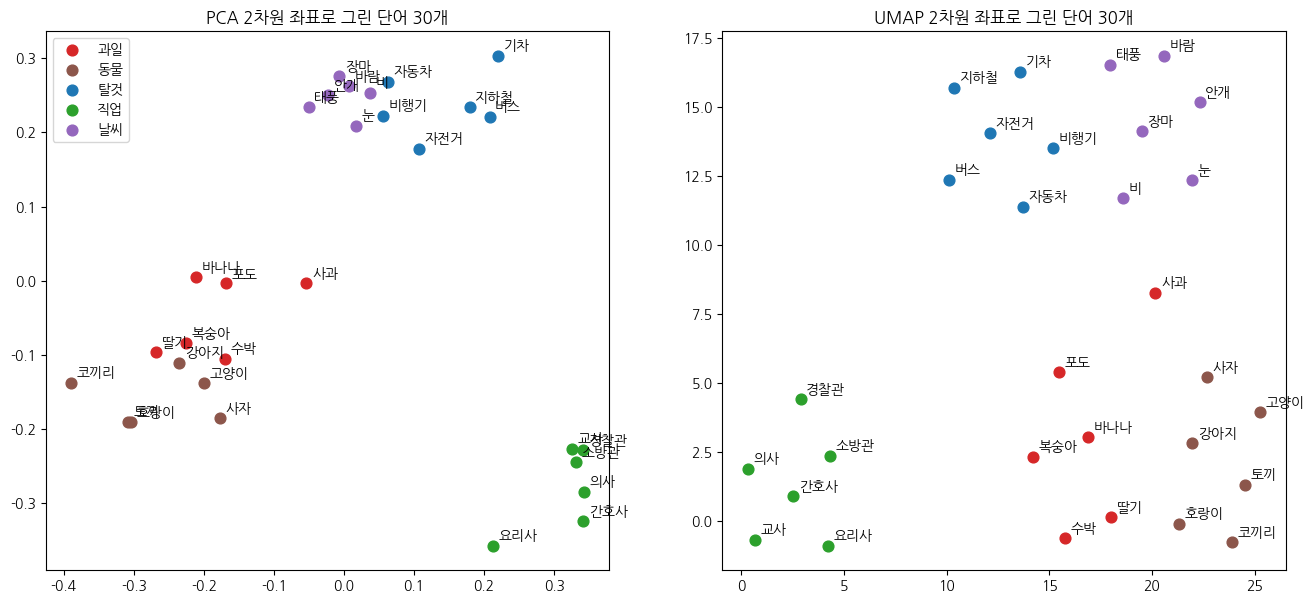

In [ ]:
colors = dict(zip(words_by_group, ["tab:red", "tab:brown", "tab:blue", "tab:green", "tab:purple"]))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, xy, title in zip(axes, [xy_pca, xy_umap], ["PCA", "UMAP"]):
    for g in words_by_group:
        m = [k for k in range(30) if groups[k] == g]
        ax.scatter(xy[m, 0], xy[m, 1], c=colors[g], label=g, s=60)
    for k, w in enumerate(words):
        ax.annotate(w, xy[k], fontsize=10, xytext=(4, 4), textcoords="offset points")
    ax.set_title(f"{title} 2차원 좌표로 그린 단어 30개")
axes[0].legend()
plt.show()

- 같은 색(같은 범주)의 단어가 한곳에 모였는지 확인합니다.
- 다른 색 사이에 있는 단어는 「4. 최근접 이웃 검색」 표에서 그 단어의 이웃을 다시 확인합니다.

## 6. 군집화

**군집화(clustering)** 는 정답 범주를 주지 않고 가까운 벡터끼리 같은 군집(cluster)으로 나누는 방법입니다. 방법 3가지를 같은 벡터에 적용합니다.

| 방법 | 나누는 방식 | 미리 정하는 값 |
|---|---|---|
| K-평균(K-Means) | 중심 k 개를 정하고, 단어마다 가장 가까운 중심에 배정 | 군집 수 k |
| 계층적 군집(Agglomerative) | 가장 가까운 두 군집을 하나씩 합쳐 가다 k 개에서 멈춤 | 군집 수 k, 군집 사이 거리 계산법 |
| HDBSCAN | 가까운 벡터가 최소 군집 크기 이상 모인 곳만 군집으로 정하고, 나머지는 이상치(−1)로 분류 | 최소 군집 크기 |

**조정 랜드 지수(Adjusted Rand Index, ARI)** 는 군집 결과가 실제 범주와 얼마나 같은지를 나타내는 값입니다. 군집 결과와 실제 범주가 완전히 같으면 1, 무작위로 나눈 수준이면 0 근처입니다. 군집 번호와는 상관이 없고(과일이 0번이든 3번이든), 같은 범주의 단어가 같은 군집에 들어갔는지만 계산에 반영합니다.

In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering, HDBSCAN
from sklearn.metrics import adjusted_rand_score

methods = {
    "K-평균": KMeans(n_clusters=5, n_init=10, random_state=0),
    "계층적 군집": AgglomerativeClustering(n_clusters=5, metric="cosine", linkage="average"),
    "HDBSCAN": HDBSCAN(min_cluster_size=3),
}
labels = {name: m.fit_predict(emb) for name, m in methods.items()}

pd.DataFrame([
    [name, len(set(lab) - {-1}), int((lab == -1).sum()), round(adjusted_rand_score(groups, lab), 3)]
    for name, lab in labels.items()
], columns=["방법", "군집 수", "이상치 수", "ARI"])

,방법,군집 수,이상치 수,ARI
0,K-평균,5,0,0.833
1,계층적 군집,5,0,0.716
2,HDBSCAN,3,7,0.716


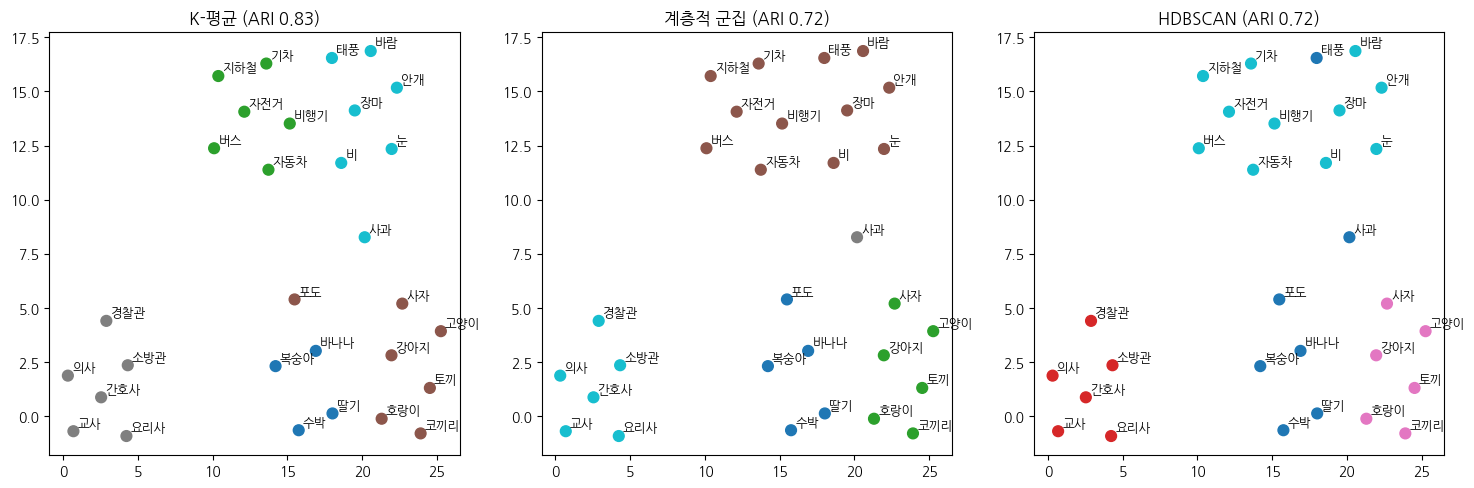

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (name, lab) in zip(axes, labels.items()):
    ax.scatter(xy_umap[:, 0], xy_umap[:, 1], c=lab, cmap="tab10", s=60)
    for k, w in enumerate(words):
        ax.annotate(w, xy_umap[k], fontsize=9, xytext=(3, 3), textcoords="offset points")
    ax.set_title(f"{name} (ARI {adjusted_rand_score(groups, lab):.2f})")
plt.show()

점 위치는 「5. 2차원 시각화(PCA · UMAP)」의 UMAP 좌표 그대로이고, 색은 각 방법이 나눈 군집을 나타냅니다. HDBSCAN 에서 이상치(−1)로 분류한 단어도 한 가지 색으로 칠해집니다.

**덴드로그램(dendrogram)** 은 계층적 군집에서 군집이 합쳐지는 순서와 그때의 거리를 나무 모양으로 그린 그림입니다. 세로축은 두 군집이 합쳐질 때의 코사인 거리입니다. 아래쪽에서 일찍 합쳐진 단어일수록 가깝습니다.

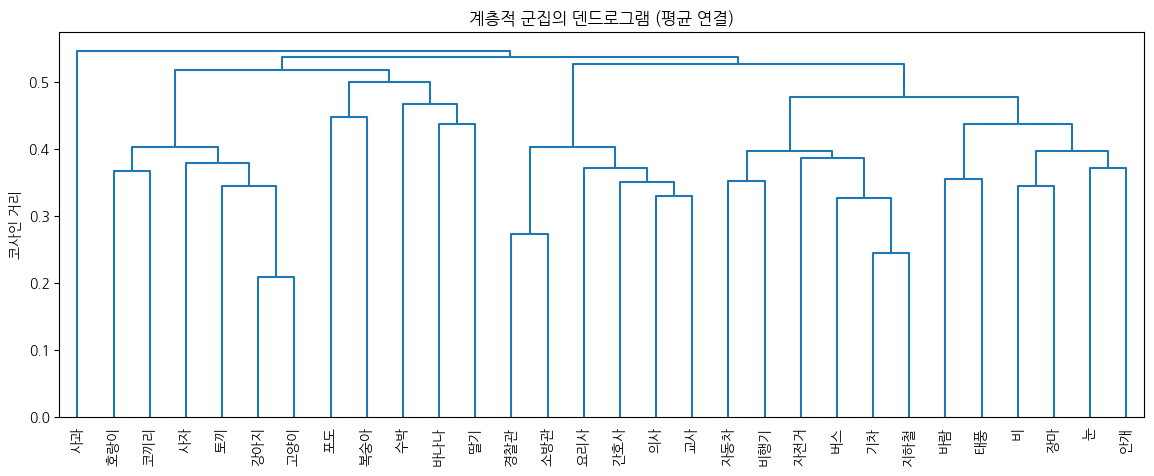

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(emb, method="average", metric="cosine")
plt.figure(figsize=(14, 5))
dendrogram(Z, labels=words, leaf_rotation=90, color_threshold=0, above_threshold_color="tab:blue")
plt.ylabel("코사인 거리")
plt.title("계층적 군집의 덴드로그램 (평균 연결)")
plt.show()

- 세 방법 가운데 ARI 가 가장 높은 방법은 무엇인가요?
- 실제 범주와 다른 군집에 들어간 단어는 무엇인가요? 첫 토큰이 같은 단어끼리 가까웠던 「4. 최근접 이웃 검색」의 결과로 설명되나요?
- HDBSCAN 이 이상치로 분류한 단어는 어느 범주에 많나요?

## 7. 모델을 바꾸면 결과가 달라진다

같은 단어 30개를 모델 3개로 각각 벡터로 바꿔 결과를 비교합니다. multilingual-e5 는 학습할 때 입력 앞에 `query: ` 를 썼기 때문에 같은 형식으로 입력합니다.

In [ ]:
candidates = {
    "nlpai-lab/KURE-v1": "",
    "intfloat/multilingual-e5-small": "query: ",
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2": "",
}

rows = []
for name, prefix in candidates.items():
    m = SentenceTransformer(name, device=device)
    e = m.encode([prefix + w for w in words], normalize_embeddings=True)
    s = e @ e.T
    same = np.mean([s[i, j] for i in range(30) for j in range(30) if i != j and groups[i] == groups[j]])
    diff = np.mean([s[i, j] for i in range(30) for j in range(30) if groups[i] != groups[j]])
    ari = adjusted_rand_score(groups, KMeans(n_clusters=5, n_init=10, random_state=0).fit_predict(e))
    rows.append([name.split("/")[-1], e.shape[1], round(same, 3), round(diff, 3), round(ari, 3)])

pd.DataFrame(rows, columns=["모델", "차원", "같은 범주 평균 코사인", "다른 범주 평균 코사인", "K-평균 ARI"])

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 9.08MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

,모델,차원,같은 범주 평균 코사인,다른 범주 평균 코사인,K-평균 ARI
0,KURE-v1,1024,0.592,0.471,0.833
1,multilingual-e5-small,384,0.823,0.807,0.222
2,paraphrase-multilingual-MiniLM-L12-v2,384,0.499,0.382,0.159


- 모델마다 코사인 값의 범위가 다릅니다. multilingual-e5-small 은 다른 범주 쌍의 평균도 0.8 을 넘습니다. 그래서 「코사인 0.8 이상이면 비슷하다」 같은 기준은 모델마다 다시 정합니다.
- 평균 코사인 두 개만으로는 범주를 잘 구분하는지 알 수 없습니다. MiniLM 은 두 평균의 차이가 KURE-v1 과 비슷하지만 ARI 는 0.16 정도로 낮습니다. 같은 범주 안에서도 쌍마다 코사인이 크게 다르기 때문입니다.
- 단어 하나만 입력하는 과제에서는 리더보드 순위가 그대로 나오지 않을 수 있습니다. 모델은 내 자료로 직접 비교해 고릅니다.

## 8. 직접 해 보기

아래 빈 셀에 코드를 써서 실행해 봅니다. 위 셀의 코드를 복사해 고쳐 써도 됩니다.

1. **단어 바꾸기**: `words_by_group` 을 관심 있는 분야의 단어로 바꿉니다. 범주 4～6개, 범주마다 5～6개면 됩니다. 그다음 「2. 단어 30개의 임베딩」부터 「6. 군집화」까지 셀을 다시 실행합니다. ARI 는 얼마이고, 다른 범주의 군집에 들어간 단어는 무엇인가요?
2. **뜻이 둘인 단어**: 「배」(먹는 배 · 타는 배)와 「눈」(내리는 눈 · 보는 눈)의 이웃을 찾아봅니다. 「배가 고프다」 · 「배를 타다」처럼 문장으로 입력하면 이웃이 어떻게 바뀌나요?
3. **문장 입력하기**: 단어 대신 짧은 문장을 입력하고 코사인을 비교합니다. 예를 들면 「배송이 빨라요」, 「택배가 하루 만에 왔어요」, 「배송이 너무 느려요」입니다. 뜻이 반대인 두 문장의 코사인은 얼마인가요?

In [ ]:
# 1. 단어 바꾸기

In [ ]:
# 2. 뜻이 둘인 단어: 힌트 — model.encode([...], normalize_embeddings=True) 와 nn.kneighbors(...)

In [ ]:
# 3. 문장 입력하기: 힌트 — 문장 벡터끼리 내적(@)을 구하면 코사인입니다

## 정리

- 임베딩 모델은 단어나 문장을 숫자 수백～수천 개의 벡터로 바꿉니다. 숫자 하나하나보다 벡터끼리의 비교가 중요합니다.
- L2 정규화한 벡터는 내적이 곧 코사인 유사도이고, 코사인 거리 · 유클리드 거리 어느 쪽으로 찾아도 이웃 순서가 같습니다.
- 단어 하나만 입력하면 첫 토큰이 같은 단어끼리 가깝게 나올 수 있습니다.
- 2차원 그림으로는 범주끼리 모이는지만 확인하고, 두 단어가 얼마나 가까운지는 원래 벡터의 코사인으로 판단합니다.
- 군집화 결과는 방법과 모델에 따라 달라집니다. 실제 범주와의 일치는 ARI 로 확인합니다.
- 코사인 값의 범위는 모델마다 다르니, 기준값은 쓰는 모델과 자료로 다시 정합니다.

## 참고한 자료

- Hugging Face LLM Course, [Semantic search with FAISS](https://huggingface.co/learn/llm-course/chapter5/6): 임베딩을 만들고 가까운 글을 찾는 흐름
- Sentence Transformers, [Semantic Textual Similarity](https://sbert.net/docs/sentence_transformer/usage/semantic_textual_similarity.html) · [Clustering](https://sbert.net/examples/sentence_transformer/applications/clustering/README.html): 코사인 유사도 계산과 K-평균 · 계층적 군집 예제
- Google Machine Learning Crash Course, [Embeddings](https://developers.google.com/machine-learning/crash-course/embeddings): 임베딩 공간에서 가까움의 뜻
- scikit-learn, [Clustering](https://scikit-learn.org/stable/modules/clustering.html) · [군집 방법 비교 예제](https://scikit-learn.org/stable/auto_examples/cluster/plot_cluster_comparison.html): 군집 방법별 특징